<a href="https://colab.research.google.com/github/sadhyasora-bit/Fraud-Detection_Model/blob/main/notebook/02_Preprocessing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 02. Data Preprocessing

Notebook ini bertujuan untuk mempersiapkan dataset Credit Card Fraud Detection
sebelum digunakan dalam proses pemodelan.

Tahapan preprocessing meliputi:
1. Dataset loading
2. Data quality checking
3. Duplicate handling
4. Feature and target separation
5. Train-validation-test splitting
6. Feature scaling

## 1. Import library dan download dataset

In [11]:
# Import libraries
import os
import kagglehub
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

import warnings
warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42

print("Libraries imported successfully!")

Libraries imported successfully!


In [12]:
# Download dataset
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")

# Load dataset
file_path = os.path.join(path, "creditcard.csv")
df = pd.read_csv(file_path)

print("Dataset berhasil dimuat!")
print("Ukuran dataset:", df.shape)

df.head()

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Dataset berhasil dimuat!
Ukuran dataset: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [13]:
# Memeriksa informasi dataset
print("Dataset Information:")
df.info()

print("\nMissing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  fl

## 2. Duplicate handling

In [14]:
# Menghapus data duplikat
df_clean = df.drop_duplicates().copy()

print("Jumlah data sebelum penghapusan:", len(df))
print("Jumlah data setelah penghapusan:", len(df_clean))
print("Jumlah data yang dihapus:", len(df) - len(df_clean))
print("Sisa data duplikat:", df_clean.duplicated().sum())

Jumlah data sebelum penghapusan: 284807
Jumlah data setelah penghapusan: 283726
Jumlah data yang dihapus: 1081
Sisa data duplikat: 0


In [15]:
# Distribusi kelas setelah duplicate handling
class_distribution = pd.DataFrame({
    "Jumlah Data": df_clean["Class"].value_counts(),
    "Persentase (%)": df_clean["Class"].value_counts(normalize=True) * 100
})

print(class_distribution)
print("\nUkuran dataset:", df_clean.shape)

       Jumlah Data  Persentase (%)
Class                             
0           283253        99.83329
1              473         0.16671

Ukuran dataset: (283726, 31)


In [17]:
# Memisahkan fitur dan target
X = df_clean.drop(columns=["Class"])
y = df_clean["Class"]

print("Feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Feature shape: (283726, 30)
Target shape: (283726,)

Feature columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


In [18]:
# Split 1: Training (70%) dan Temporary (30%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=RANDOM_STATE
)

# Split 2: Validation (15%) dan Testing (15%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=RANDOM_STATE
)

print("Data splitting completed!")

print("\nTraining:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

Data splitting completed!

Training: (198608, 30)
Validation: (42559, 30)
Testing: (42559, 30)


In [20]:
# Membandingkan distribusi kelas
split_distribution = pd.DataFrame({
    "Training": y_train.value_counts(),
    "Validation": y_val.value_counts(),
    "Testing": y_test.value_counts()
})

split_distribution.loc["Total"] = split_distribution.sum()

print(split_distribution)

       Training  Validation  Testing
Class                               
0        198277       42488    42488
1           331          71       71
Total    198608       42559    42559


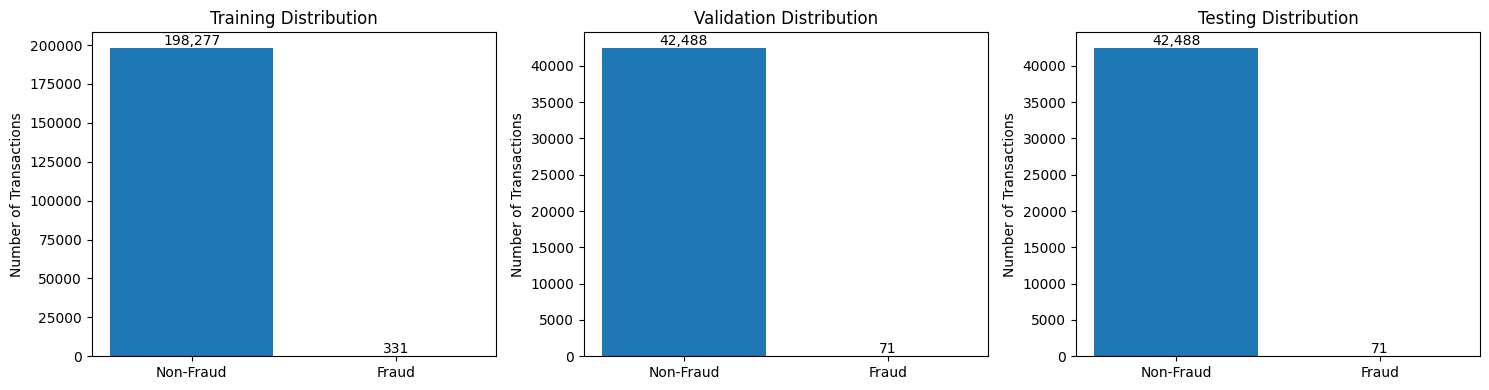

In [21]:
import matplotlib.pyplot as plt

# Visualisasi distribusi kelas setiap subset
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

datasets = [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]

for ax, (name, target) in zip(axes, datasets):
    counts = target.value_counts().sort_index()

    ax.bar(
        ["Non-Fraud", "Fraud"],
        counts.values
    )

    ax.set_title(f"{name} Distribution")
    ax.set_ylabel("Number of Transactions")

    for i, value in enumerate(counts.values):
        ax.text(i, value, f"{value:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

## Feature scaling menggunakan RobustScaler

In [22]:
# Menentukan fitur yang akan di-scaling
scaling_features = ["Time", "Amount"]

# Membuat scaler
scaler = RobustScaler()

# Salin dataset agar data asli tidak berubah
X_train_scaled = X_train.copy()
X_val_scaled = X_val.copy()
X_test_scaled = X_test.copy()

# Fit scaler hanya pada training data
X_train_scaled[scaling_features] = scaler.fit_transform(
    X_train[scaling_features]
)

# Transform validation dan testing menggunakan scaler training
X_val_scaled[scaling_features] = scaler.transform(
    X_val[scaling_features]
)

X_test_scaled[scaling_features] = scaler.transform(
    X_test[scaling_features]
)

print("Feature scaling completed!")

Feature scaling completed!


In [23]:
# Membandingkan statistik sebelum dan sesudah scaling
print("Before Scaling:")
display(X_train[scaling_features].describe())

print("\nAfter Scaling:")
display(X_train_scaled[scaling_features].describe())

Before Scaling:


,Time,Amount
count,198608.000000,198608.000000
mean,94915.874194,88.321679
std,47485.527892,242.613439
min,0.000000,0.000000
25%,54273.750000,5.700000
50%,84857.000000,22.080000
75%,139372.250000,77.710000
max,172792.000000,18910.000000



After Scaling:


,Time,Amount
count,198608.000000,198608.000000
mean,0.118203,0.919896
std,0.558007,3.369163
min,-0.997162,-0.306624
25%,-0.359386,-0.227468
50%,0.000000,0.000000
75%,0.640614,0.772532
max,1.033332,262.295792


In [24]:
# Memastikan tidak ada missing values
print("Missing Values:")
print("Training  :", X_train_scaled.isnull().sum().sum())
print("Validation:", X_val_scaled.isnull().sum().sum())
print("Testing   :", X_test_scaled.isnull().sum().sum())

# Memastikan distribusi kelas tetap asli
print("\nClass Distribution:")
print("Training:\n", y_train.value_counts())
print("Validation:\n", y_val.value_counts())
print("Testing:\n", y_test.value_counts())

# Memastikan ukuran data
print("\nFinal Dataset Shapes:")
print("X_train:", X_train_scaled.shape)
print("X_val  :", X_val_scaled.shape)
print("X_test :", X_test_scaled.shape)

Missing Values:
Training  : 0
Validation: 0
Testing   : 0

Class Distribution:
Training:
 Class
0    198277
1       331
Name: count, dtype: int64
Validation:
 Class
0    42488
1       71
Name: count, dtype: int64
Testing:
 Class
0    42488
1       71
Name: count, dtype: int64

Final Dataset Shapes:
X_train: (198608, 30)
X_val  : (42559, 30)
X_test : (42559, 30)


In [25]:
# Membuat folder penyimpanan
output_dir = "/content/preprocessed_data"
os.makedirs(output_dir, exist_ok=True)

# Menyimpan data hasil preprocessing
X_train_scaled.to_csv(
    f"{output_dir}/X_train.csv", index=False
)

X_val_scaled.to_csv(
    f"{output_dir}/X_val.csv", index=False
)

X_test_scaled.to_csv(
    f"{output_dir}/X_test.csv", index=False
)

y_train.to_csv(
    f"{output_dir}/y_train.csv", index=False
)

y_val.to_csv(
    f"{output_dir}/y_val.csv", index=False
)

y_test.to_csv(
    f"{output_dir}/y_test.csv", index=False
)

print("Seluruh data preprocessing berhasil disimpan!")
print("Lokasi:", output_dir)

Seluruh data preprocessing berhasil disimpan!
Lokasi: /content/preprocessed_data


In [26]:
import shutil
from google.colab import files

# Membuat file ZIP
zip_path = shutil.make_archive(
    "/content/preprocessed_data",
    "zip",
    output_dir
)

# Download ZIP
files.download(zip_path)

print("ZIP berhasil dibuat:", zip_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ZIP berhasil dibuat: /content/preprocessed_data.zip
